# NF-ToN-IoT v3 Dataset Analysis

**Repository**: TRENCH-IDS Research  
**Dataset**: `v3/ToN-IoT/NF-ToN-IoT-v3/data/NF-ToN-IoT-v3.csv`  
**Feature reference**: `v3/ToN-IoT/NF-ToN-IoT-v3/data/NetFlow_v3_Features.csv`

## Who this notebook is for

Anyone who wants a complete, beginner-friendly picture of the NF-ToN-IoT v3 dataset. Every cell does **one small thing** and explains what it shows.

## What you will learn

- What a network **flow** is and what the 55 columns mean
- Exact benign vs. attack counts over the full 27.5M-row dataset
- Every attack sub-type, checked **all at once or one at a time**
- **Whether attacks come in blocks or are mixed** once benign traffic is removed
- Protocol, port, IP and time-of-day patterns
- How benign and attack flows differ in size, duration and speed

> **Important:** the CSV is stored in time order. The first 1M rows contain only benign + `scanning` traffic. That is why this notebook scans the **full file once** before doing attack-level analysis.


In [79]:
import os
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

candidates = [
    'v3/ToN-IoT/NF-ToN-IoT-v3/data/NF-ToN-IoT-v3.csv',
    '../v3/ToN-IoT/NF-ToN-IoT-v3/data/NF-ToN-IoT-v3.csv',
    '../../v3/ToN-IoT/NF-ToN-IoT-v3/data/NF-ToN-IoT-v3.csv',
]
DATA_PATH = next((c for c in candidates if os.path.exists(c)), None)
if DATA_PATH is None:
    raise FileNotFoundError('Dataset not found. Tried: ' + str(candidates))

FEATURES_PATH = os.path.join(os.path.dirname(DATA_PATH), 'NetFlow_v3_Features.csv')
print('Using dataset :', DATA_PATH)
print('Using features:', FEATURES_PATH)


Using dataset : ../../v3/ToN-IoT/NF-ToN-IoT-v3/data/NF-ToN-IoT-v3.csv
Using features: ../../v3/ToN-IoT/NF-ToN-IoT-v3/data\NetFlow_v3_Features.csv


## What is this dataset?

NF-ToN-IoT v3 is a **network-flow** dataset for IoT intrusion detection.

- A **flow** is one conversation between a source and a destination (same IPs, ports and protocol).
- Each **row** is one flow.
- Each **column** is one measurement about that flow.

### Size and labels

| Item | Value |
|---|---|
| Rows (flows) | ~27.5 million |
| Columns | 55 = 53 flow measurements + 2 labels |
| `Label` | `0` = benign, `1` = attack |
| `Attack` | Attack sub-type name (benign rows say `Benign`) |

### Attack sub-types

| Attack | Meaning |
|---|---|
| `scanning` | Probe for open ports / services |
| `dos` | Denial of Service from one source |
| `ddos` | Distributed DoS from many sources |
| `injection` | Malicious commands/queries (e.g. SQL injection) |
| `password` | Brute-force / credential attacks |
| `xss` | Cross-Site Scripting |
| `ransomware` | File-encrypting malware |
| `Backdoor` | Hidden remote access |
| `mitm` | Man-in-the-Middle interception |


## 1. Feature reference

`NetFlow_v3_Features.csv` explains every one of the 53 measurement columns.


In [80]:
features_df = pd.read_csv(FEATURES_PATH)
print(f'Documented flow features: {len(features_df)}')
print(f'Plus 2 labels -> {len(features_df) + 2} total columns')
features_df.head(10)


Documented flow features: 53
Plus 2 labels -> 55 total columns


,Feature,Description
0,IPV4_SRC_ADDR,IPv4 source address
1,IPV4_DST_ADDR,IPv4 destination address
2,L4_SRC_PORT,IPv4 source port number
3,L4_DST_PORT,IPv4 destination port number
4,PROTOCOL,IP protocol identifier byte
5,L7_PROTO,Layer 7 protocol (numeric)
6,IN_BYTES,Incoming number of bytes
7,OUT_BYTES,Outgoing number of bytes
8,IN_PKTS,Incoming number of packets
9,OUT_PKTS,Outgoing number of packets


## 2. First look at the raw file

Load the first 1,000,000 rows to inspect the schema. This keeps memory small and preserves row order.


In [81]:
SAMPLE_ROWS = 1_000_000
df_sample = pd.read_csv(DATA_PATH, nrows=SAMPLE_ROWS)

print(f'Sample: {len(df_sample):,} rows x {df_sample.shape[1]} columns')
df_sample.head(3)


Sample: 1,000,000 rows x 55 columns


,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,...,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1556028590618,1556028590618,192.168.1.32,41315,192.168.1.169,10010,6,0,44,1,...,0,0,0,0,0,0,0,0,0,Benign
1,1556028590618,1556028590621,192.168.1.32,41315,192.168.1.194,49400,6,0,44,1,...,0,0,0,0,0,0,0,0,0,Benign
2,1556028590618,1556028590621,192.168.1.32,41315,192.168.1.193,8008,6,161,44,1,...,0,0,0,0,0,0,0,0,1,scanning


### Why the first sample is not enough

Because the file is **time-ordered**, the first 1M rows cover only the first capture window. Check which attack types appear in it.


In [82]:
sample_attacks = (
    df_sample.loc[df_sample['Label'] == 1, 'Attack']
    .value_counts()
    .rename_axis('Attack')
    .to_frame('Flows')
)
print('Attack types in the first 1M rows:')
display(sample_attacks)
print('Only the first capture window is visible here, so full-file scanning is required.')


Attack types in the first 1M rows:


,Flows
Attack,
scanning,249689


Only the first capture window is visible here, so full-file scanning is required.


## 3. Column groups at a glance

The 55 columns belong to a few logical families. This is the vocabulary an IDS model sees.


In [83]:
feature_groups = {
    'Addresses': ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR'],
    'Ports': ['L4_SRC_PORT', 'L4_DST_PORT'],
    'Protocol': ['PROTOCOL', 'L7_PROTO'],
    'Traffic volume': ['IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS'],
    'Duration': ['FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT'],
    'TCP flags': ['TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS'],
    'TTL': ['MIN_TTL', 'MAX_TTL'],
    'Packet size': ['LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN'],
    'Retransmissions': ['RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS',
                        'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS'],
    'Throughput': ['SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT'],
    'Bytes/sec': ['SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES'],
    'Packet-size histogram': ['NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES',
                              'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES',
                              'NUM_PKTS_1024_TO_1514_BYTES'],
    'TCP window': ['TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT'],
    'ICMP/DNS/FTP': ['ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID',
                     'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE'],
    'Timestamps': ['FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS'],
    'Inter-arrival time': ['SRC_TO_DST_IAT_MIN', 'SRC_TO_DST_IAT_MAX',
                           'SRC_TO_DST_IAT_AVG', 'SRC_TO_DST_IAT_STDDEV',
                           'DST_TO_SRC_IAT_MIN', 'DST_TO_SRC_IAT_MAX',
                           'DST_TO_SRC_IAT_AVG', 'DST_TO_SRC_IAT_STDDEV'],
    'Labels': ['Label', 'Attack'],
}

for group, cols in feature_groups.items():
    present = [c for c in cols if c in df_sample.columns]
    print(f'{group:22s}: {len(present)}')
print('Total accounted for :', sum(len([c for c in v if c in df_sample.columns])
                                   for v in feature_groups.values()))


Addresses             : 2
Ports                 : 2
Protocol              : 2
Traffic volume        : 4
Duration              : 3
TCP flags             : 3
TTL                   : 2
Packet size           : 4
Retransmissions       : 4
Throughput            : 2
Bytes/sec             : 2
Packet-size histogram : 5
TCP window            : 2
ICMP/DNS/FTP          : 6
Timestamps            : 2
Inter-arrival time    : 8
Labels                : 2
Total accounted for : 55


## 4. One full-dataset scan

This single pass over the CSV collects everything the rest of the notebook needs:

1. Exact `Label` and `Attack` counts for all 27.5M rows.
2. The complete **attack sequence** (start time + attack type) for ordering analysis.
3. A **stratified sample of every attack type** (up to 20k rows each) for per-attack feature stats.
4. Full-file protocol and port counters.

It streams in 500k-row chunks, so memory stays modest.


In [84]:
MAX_PER_TYPE = 20_000
SCAN_COLS = [
    'FLOW_START_MILLISECONDS', 'Attack', 'Label',
    'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS',
    'FLOW_DURATION_MILLISECONDS', 'PROTOCOL', 'L4_SRC_PORT', 'L4_DST_PORT',
    'IPV4_SRC_ADDR', 'IPV4_DST_ADDR',
    'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT',
    'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT',
]

label_counts = Counter()
attack_counts = Counter()
proto_counts = Counter()
dst_port_counts = Counter()
src_port_counts = Counter()

attack_to_code = {}
code_parts, time_parts, sample_parts = [], [], []
sampled = {}
total_rows = 0

for chunk in pd.read_csv(DATA_PATH, chunksize=500_000, usecols=SCAN_COLS):
    total_rows += len(chunk)
    label_counts.update(chunk['Label'].value_counts().to_dict())
    proto_counts.update(chunk['PROTOCOL'].value_counts().to_dict())
    dst_port_counts.update(chunk['L4_DST_PORT'].value_counts().to_dict())
    src_port_counts.update(chunk['L4_SRC_PORT'].value_counts().to_dict())

    atk = chunk[chunk['Label'] == 1]
    if len(atk) == 0:
        continue

    attack_counts.update(atk['Attack'].value_counts().to_dict())
    for name in atk['Attack'].unique():
        attack_to_code.setdefault(name, len(attack_to_code))

    code_parts.append(atk['Attack'].map(attack_to_code).to_numpy(dtype=np.int16))
    time_parts.append(atk['FLOW_START_MILLISECONDS'].to_numpy(dtype=np.int64))

    for name, group in atk.groupby('Attack', sort=False):
        have = sampled.get(name, 0)
        if have < MAX_PER_TYPE:
            take = group.head(MAX_PER_TYPE - have)
            sample_parts.append(take)
            sampled[name] = have + len(take)

    if total_rows % 5_000_000 < 500_000:
        print(f'  scanned {total_rows:,} rows ...')

attack_codes = np.concatenate(code_parts)
attack_times = np.concatenate(time_parts)
df_attacks = pd.concat(sample_parts, ignore_index=True)
code_to_attack = {v: k for k, v in attack_to_code.items()}

# Put attacks in true time order (CSV is nearly ordered; sorting is safe).
order = np.argsort(attack_times, kind='stable')
attack_times = attack_times[order]
attack_codes = attack_codes[order]

print(f'Full rows          : {total_rows:,}')
print(f'Attack flows       : {len(attack_codes):,}')
print(f'Attack types       : {len(attack_to_code)} -> {sorted(attack_to_code)}')
print(f'Stratified sample  : {len(df_attacks):,} attack rows')


  scanned 5,000,000 rows ...
  scanned 10,000,000 rows ...
  scanned 15,000,000 rows ...
  scanned 20,000,000 rows ...
  scanned 25,000,000 rows ...
Full rows          : 27,520,260
Attack flows       : 10,728,046
Attack types       : 9 -> ['Backdoor', 'ddos', 'dos', 'injection', 'mitm', 'password', 'ransomware', 'scanning', 'xss']
Stratified sample  : 149,984 attack rows


## 5. Binary label distribution (full dataset)

Exact benign vs. attack counts across all 27.5M rows.


,Label,Flows,Class,Percent
0,0,16792214,Benign,61.02
1,1,10728046,Attack,38.98


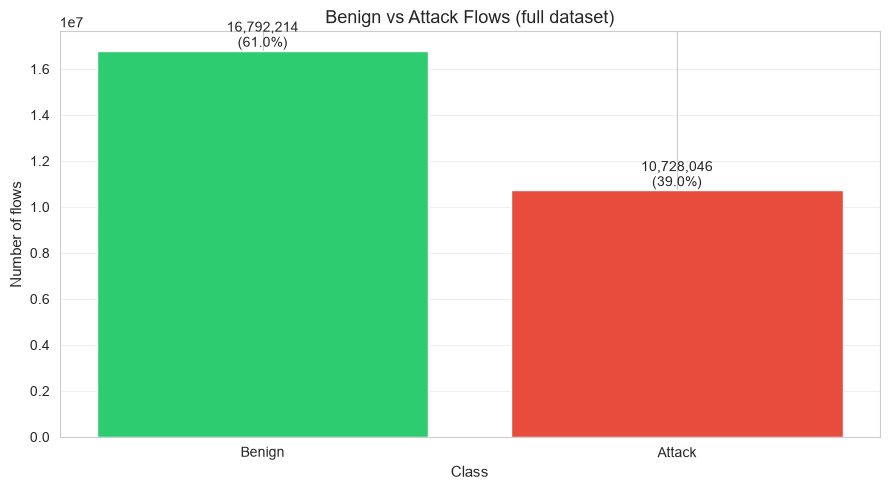

In [85]:
label_df = pd.DataFrame(
    [(int(k), v) for k, v in label_counts.items()],
    columns=['Label', 'Flows'],
)
label_df['Class'] = label_df['Label'].map({0: 'Benign', 1: 'Attack'})
label_df['Percent'] = (label_df['Flows'] / total_rows * 100).round(2)
label_df = label_df.sort_values('Flows', ascending=False)
display(label_df)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#2ecc71' if c == 'Benign' else '#e74c3c' for c in label_df['Class']]
bars = ax.bar(label_df['Class'], label_df['Flows'], color=colors)
ax.set_xlabel('Class')
ax.set_ylabel('Number of flows')
ax.set_title('Benign vs Attack Flows (full dataset)')
for bar, pct in zip(bars, label_df['Percent']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f'{bar.get_height():,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Attack sub-type distribution (full dataset)

Attack rows only (benign removed). This is the table the rest of the notebook uses.


,Attack,Flows,PercentOfAttacks
0,ddos,4141256,38.60
1,xss,2834435,26.42
2,password,1594777,14.87
3,scanning,1358977,12.67
4,injection,381777,3.56
5,dos,203456,1.90
6,Backdoor,203384,1.90
7,mitm,6013,0.06
8,ransomware,3971,0.04


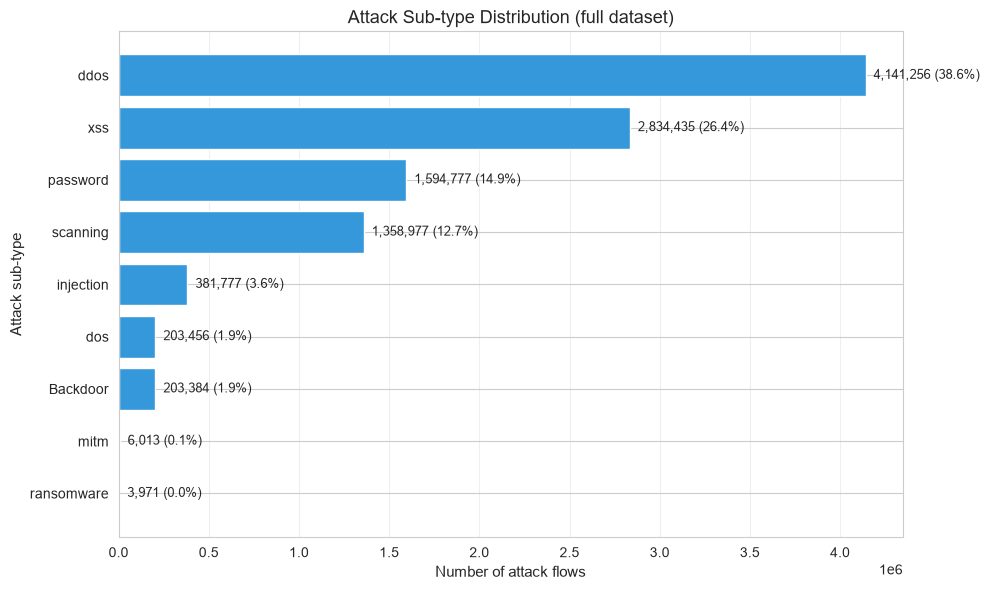

In [86]:
attack_df = pd.DataFrame(
    [(k, v) for k, v in attack_counts.items()],
    columns=['Attack', 'Flows'],
).sort_values('Flows', ascending=False)
attack_df['PercentOfAttacks'] = (attack_df['Flows'] / attack_df['Flows'].sum() * 100).round(2)
display(attack_df.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(attack_df['Attack'][::-1], attack_df['Flows'][::-1], color='#3498db')
ax.set_xlabel('Number of attack flows')
ax.set_ylabel('Attack sub-type')
ax.set_title('Attack Sub-type Distribution (full dataset)')
for i, (v, p) in enumerate(zip(attack_df['Flows'][::-1], attack_df['PercentOfAttacks'][::-1])):
    ax.text(v, i, f'  {v:,} ({p:.1f}%)', va='center', fontsize=9)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Attack ordering: sequential or mixed?

**Question:** after removing benign flows, do the same attacks arrive in long blocks, or are different attacks interleaved?

- `runs` = number of consecutive blocks of the same attack type.
- **Mixing index** = `(runs - 1) / (attack flows - 1)`.
  - `0.0` → one huge block (fully sequential).
  - `1.0` → the attack type changes at every single flow (fully mixed).

This uses the **full attack sequence**, not the first 1M rows, so all 9 attack types are included.


In [87]:
change = np.r_[True, attack_codes[1:] != attack_codes[:-1]]
run_starts = np.flatnonzero(change)
run_lengths = np.diff(np.r_[run_starts, len(attack_codes)])
run_types = attack_codes[run_starts]

n_flows = len(attack_codes)
n_runs = len(run_lengths)
mixing_index = (n_runs - 1) / (n_flows - 1)

print(f'Attack flows        : {n_flows:,}')
print(f'Consecutive blocks  : {n_runs:,}')
print(f'Mean block length   : {run_lengths.mean():,.1f} flows')
print(f'Median block length : {np.median(run_lengths):,.0f} flows')
print(f'Longest block       : {run_lengths.max():,} flows')
print(f'Mixing index        : {mixing_index:.4f}')

if mixing_index < 0.3:
    verdict = 'mostly BLOCKED / sequential'
elif mixing_index > 0.7:
    verdict = 'strongly MIXED'
else:
    verdict = 'PARTIALLY mixed'
print(f'Verdict             : {verdict}')


Attack flows        : 10,728,046
Consecutive blocks  : 9
Mean block length   : 1,192,005.1 flows
Median block length : 381,777 flows
Longest block       : 4,141,256 flows
Mixing index        : 0.0000
Verdict             : mostly BLOCKED / sequential


In [88]:
n_types = len(attack_to_code)
run_count = np.bincount(run_types, minlength=n_types)
run_sum = np.bincount(run_types, weights=run_lengths, minlength=n_types)
run_max = np.zeros(n_types, dtype=np.int64)
np.maximum.at(run_max, run_types, run_lengths)

run_table = pd.DataFrame({
    'Runs': run_count,
    'MeanRun': np.divide(run_sum, run_count, out=np.zeros(n_types), where=run_count > 0),
    'MaxRun': run_max,
}, index=[code_to_attack[i] for i in range(n_types)])
run_table.index.name = 'Attack'
run_table = run_table.sort_values('Runs', ascending=False).round(1)
display(run_table)


,Runs,MeanRun,MaxRun
Attack,,,
scanning,1,1358977.0,1358977
dos,1,203456.0,203456
injection,1,381777.0,381777
ddos,1,4141256.0,4141256
password,1,1594777.0,1594777
xss,1,2834435.0,2834435
ransomware,1,3971.0,3971
Backdoor,1,203384.0,203384
mitm,1,6013.0,6013


### Chronological block order

If `Runs` is 1 for every attack type, each attack appears as **one contiguous block**. The table and Gantt chart below show the exact order, size, and time span of each block.


In [89]:
block_rows = []
for k, start in enumerate(run_starts):
    end = start + run_lengths[k] - 1
    block_rows.append({
        'Order': k + 1,
        'Attack': code_to_attack[int(run_types[k])],
        'Flows': int(run_lengths[k]),
        'Start': pd.to_datetime(int(attack_times[start]), unit='ms'),
        'End': pd.to_datetime(int(attack_times[end]), unit='ms'),
        'Duration_min': round((int(attack_times[end]) - int(attack_times[start])) / 60_000, 2),
    })
block_df = pd.DataFrame(block_rows)
display(block_df)


,Order,Attack,Flows,Start,End,Duration_min
0,1,scanning,1358977,2019-04-23 14:09:50.618,2019-04-24 07:06:37.647,1016.78
1,2,dos,203456,2019-04-24 18:13:42.297,2019-04-25 02:50:20.576,516.64
2,3,injection,381777,2019-04-25 05:49:22.186,2019-04-25 10:14:18.788,264.94
3,4,ddos,4141256,2019-04-25 14:48:47.370,2019-04-26 05:01:10.995,852.39
4,5,password,1594777,2019-04-26 13:45:49.635,2019-04-27 03:47:44.675,841.92
5,6,xss,2834435,2019-04-27 04:54:22.396,2019-04-27 12:40:52.964,466.51
6,7,ransomware,3971,2019-04-28 03:49:53.081,2019-04-28 06:05:23.073,135.50
7,8,Backdoor,203384,2019-04-28 07:29:59.094,2019-04-29 09:45:32.443,1575.56
8,9,mitm,6013,2019-04-29 12:20:42.076,2019-04-29 14:43:05.358,142.39


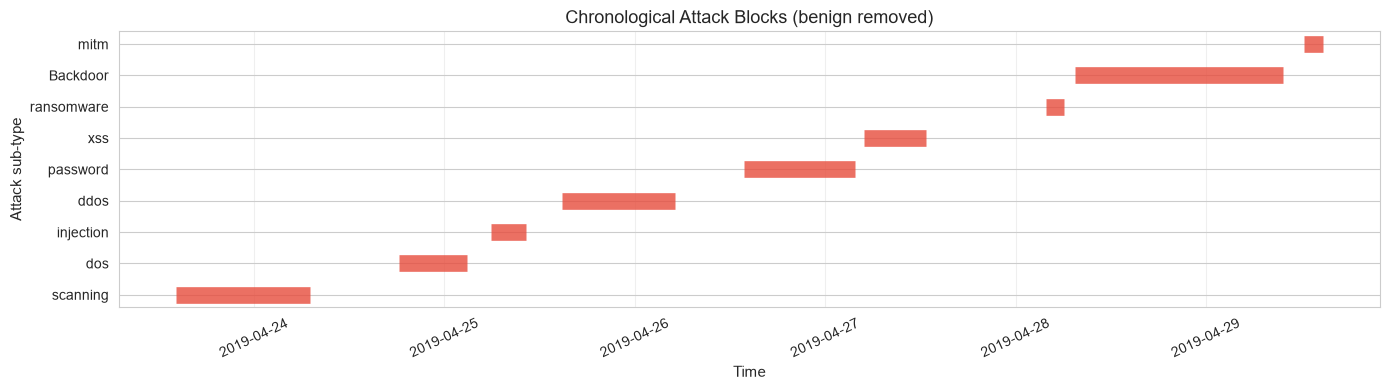

In [90]:
fig, ax = plt.subplots(figsize=(14, 4))
for _, row in block_df.iterrows():
    ax.hlines(row['Attack'], row['Start'], row['End'],
              linewidth=12, color='#e74c3c', alpha=0.8)
ax.set_xlabel('Time')
ax.set_ylabel('Attack sub-type')
ax.set_title('Chronological Attack Blocks (benign removed)')
ax.grid(axis='x', alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


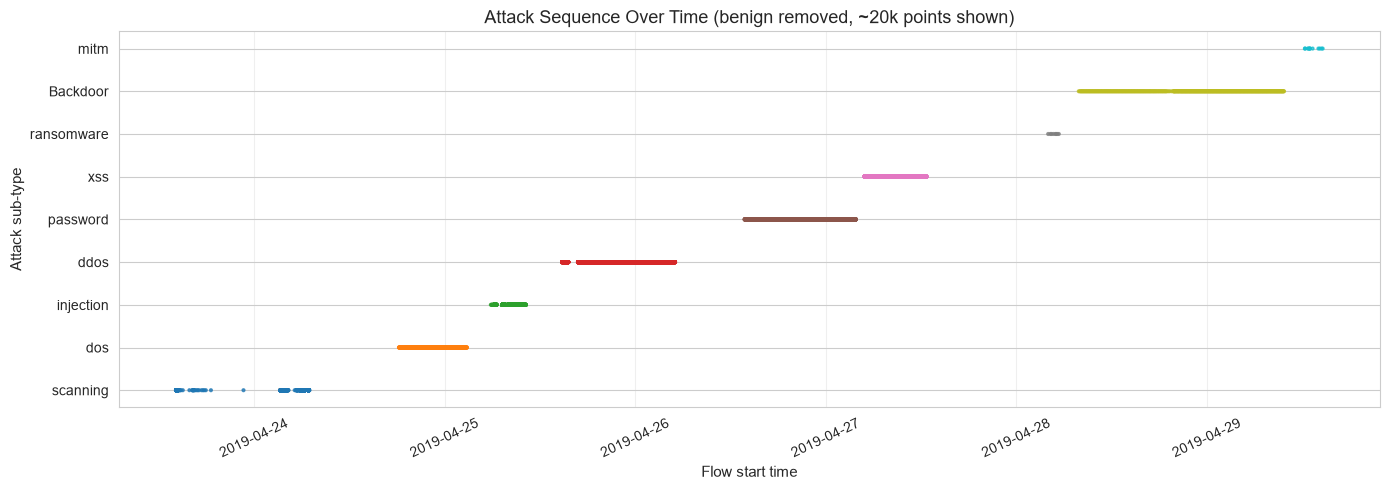

In [91]:
step = max(1, n_flows // 20_000)
tl_time = pd.to_datetime(attack_times[::step], unit='ms')
tl_code = attack_codes[::step]

fig, ax = plt.subplots(figsize=(14, 5))
ax.scatter(tl_time, tl_code, c=tl_code, cmap='tab10', s=4, alpha=0.75)
ax.set_yticks(range(n_types))
ax.set_yticklabels([code_to_attack[i] for i in range(n_types)])
ax.set_xlabel('Flow start time')
ax.set_ylabel('Attack sub-type')
ax.set_title('Attack Sequence Over Time (benign removed, ~20k points shown)')
ax.grid(axis='x', alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


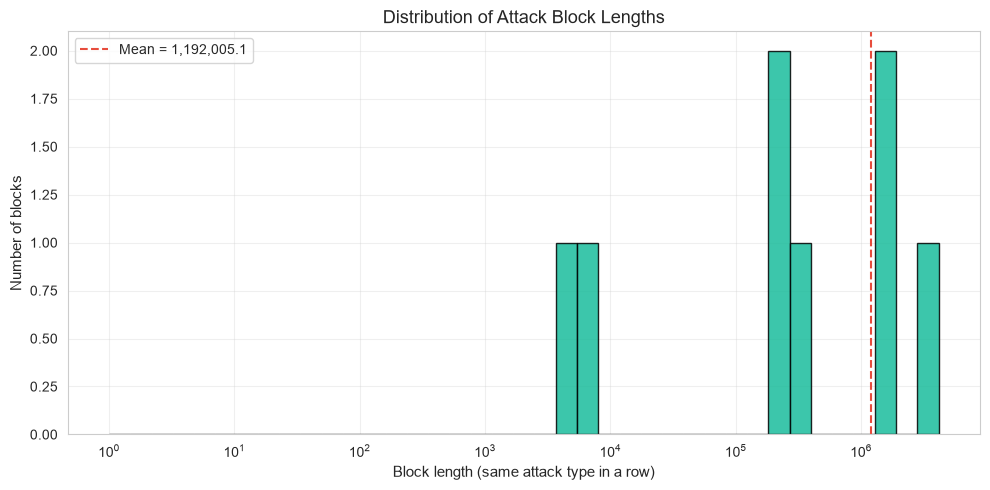

In [92]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.logspace(0, np.log10(max(int(run_lengths.max()), 2)), 40)
ax.hist(run_lengths, bins=bins, color='#1abc9c', edgecolor='black', alpha=0.85)
ax.set_xscale('log')
ax.set_xlabel('Block length (same attack type in a row)')
ax.set_ylabel('Number of blocks')
ax.set_title('Distribution of Attack Block Lengths')
ax.axvline(run_lengths.mean(), color='#e74c3c', linestyle='--',
           label=f'Mean = {run_lengths.mean():,.1f}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,scanning,dos,injection,ddos,password,xss,ransomware,Backdoor,mitm
scanning,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
dos,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
injection,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0
ddos,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0
password,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0
xss,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0
ransomware,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0
Backdoor,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0
mitm,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0


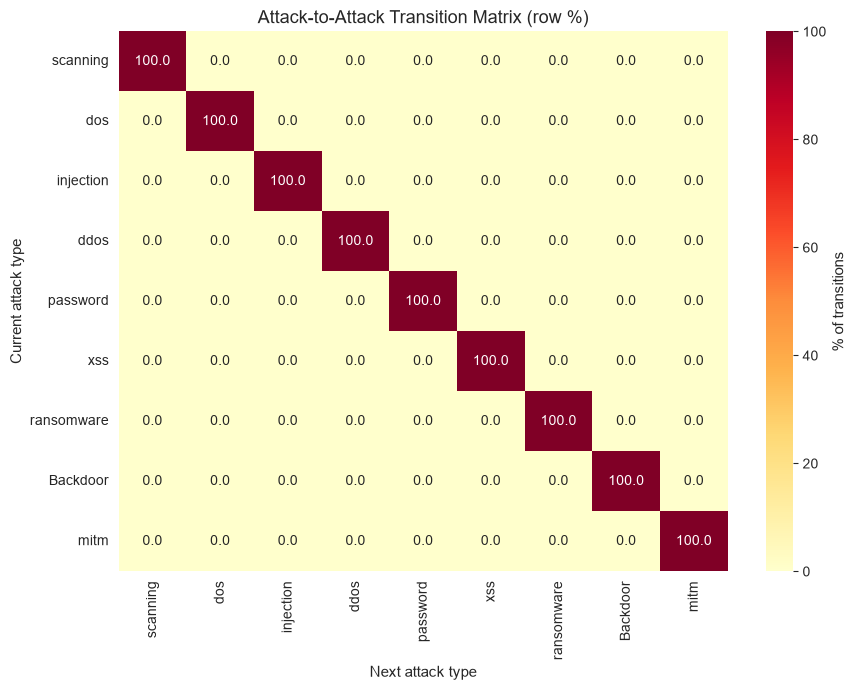

In [93]:
pair_index = attack_codes[:-1].astype(np.int64) * n_types + attack_codes[1:]
trans = np.bincount(pair_index, minlength=n_types * n_types).reshape(n_types, n_types)
row_sums = trans.sum(axis=1, keepdims=True)
trans_pct = np.divide(trans, row_sums,
                      out=np.zeros_like(trans, dtype=float), where=row_sums > 0) * 100

names = [code_to_attack[i] for i in range(n_types)]
trans_df = pd.DataFrame(trans_pct.round(1), index=names, columns=names)
display(trans_df)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(trans_df, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax,
            cbar_kws={'label': '% of transitions'})
ax.set_xlabel('Next attack type')
ax.set_ylabel('Current attack type')
ax.set_title('Attack-to-Attack Transition Matrix (row %)')
plt.tight_layout()
plt.show()


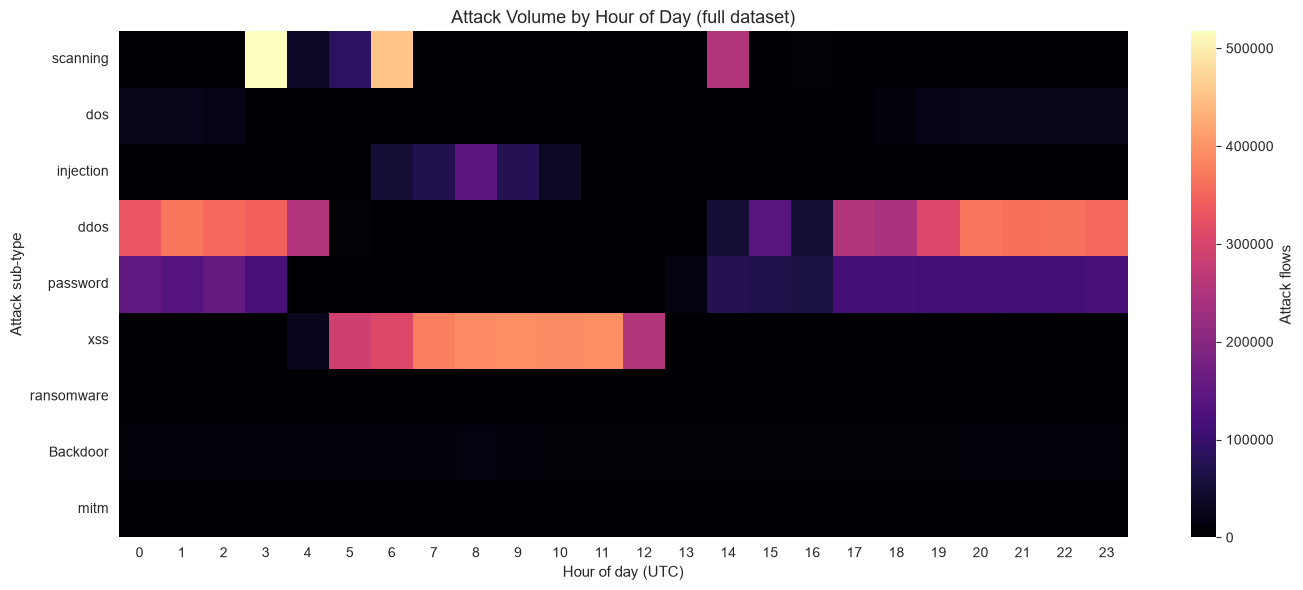

In [94]:
hour_of_day = pd.to_datetime(attack_times, unit='ms').hour
hour_table = pd.crosstab(hour_of_day, attack_codes)
hour_table.columns = [code_to_attack[c] for c in hour_table.columns]
hour_table = hour_table.reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(hour_table.T, cmap='magma', ax=ax,
            cbar_kws={'label': 'Attack flows'})
ax.set_xlabel('Hour of day (UTC)')
ax.set_ylabel('Attack sub-type')
ax.set_title('Attack Volume by Hour of Day (full dataset)')
plt.tight_layout()
plt.show()


## 8. Check all attacks at once — or one at a time

The table below has **one row per attack type and a `Selected` column**. Change `SELECTION` to analyse everything together or a single attack separately.

- `'all'` → every attack type
- `'ddos'` → one attack type
- `['ddos', 'xss']` → any subset


In [95]:
all_attacks = attack_df['Attack'].tolist()
SELECTION = 'all'          # 'all', 'ddos', or ['ddos', 'xss']

if SELECTION == 'all':
    selected_attacks = all_attacks
elif isinstance(SELECTION, str):
    selected_attacks = [SELECTION]
else:
    selected_attacks = list(SELECTION)

print('All attack types :', all_attacks)
print('Selected         :', selected_attacks)


All attack types : ['ddos', 'xss', 'password', 'scanning', 'injection', 'dos', 'Backdoor', 'mitm', 'ransomware']
Selected         : ['ddos', 'xss', 'password', 'scanning', 'injection', 'dos', 'Backdoor', 'mitm', 'ransomware']


### Per-attack summary table

One row per attack type: flow count, share of all attacks, block behaviour, unique IPs, and average flow size. This is the "all attacks at once" view.


In [96]:
summary = pd.DataFrame(index=all_attacks)
summary.index.name = 'Attack'
summary['Flows'] = [attack_counts[a] for a in all_attacks]
summary['ShareOfAttacks_%'] = (summary['Flows'] / summary['Flows'].sum() * 100).round(2)
summary['Runs'] = run_table['Runs']
summary['MeanRun'] = run_table['MeanRun']
summary['MaxRun'] = run_table['MaxRun']
summary['UniqueSrcIPs'] = df_attacks.groupby('Attack')['IPV4_SRC_ADDR'].nunique()
summary['UniqueDstIPs'] = df_attacks.groupby('Attack')['IPV4_DST_ADDR'].nunique()
summary['MeanDuration_ms'] = df_attacks.groupby('Attack')['FLOW_DURATION_MILLISECONDS'].mean().round(1)
summary['MeanIN_BYTES'] = df_attacks.groupby('Attack')['IN_BYTES'].mean().round(1)
summary['MeanOUT_BYTES'] = df_attacks.groupby('Attack')['OUT_BYTES'].mean().round(1)
summary['MeanIN_PKTS'] = df_attacks.groupby('Attack')['IN_PKTS'].mean().round(1)
summary['MeanOUT_PKTS'] = df_attacks.groupby('Attack')['OUT_PKTS'].mean().round(1)
summary['Selected'] = summary.index.isin(selected_attacks)
summary = summary.fillna(0).sort_values('Flows', ascending=False)
display(summary)


,Flows,ShareOfAttacks_%,Runs,MeanRun,MaxRun,UniqueSrcIPs,UniqueDstIPs,MeanDuration_ms,MeanIN_BYTES,MeanOUT_BYTES,MeanIN_PKTS,MeanOUT_PKTS,Selected
Attack,,,,,,,,,,,,,
ddos,4141256,38.60,1,4141256.0,4141256,4,13,83.4,264.3,261.3,3.6,1.3,True
xss,2834435,26.42,1,2834435.0,2834435,2,8,110.6,572.0,158.9,1.7,0.6,True
password,1594777,14.87,1,1594777.0,1594777,2,27,573.0,265.3,1113.8,3.6,3.8,True
scanning,1358977,12.67,1,1358977.0,1358977,10,234,20.2,47.7,9.4,1.1,0.2,True
injection,381777,3.56,1,381777.0,381777,2,11,501.8,486.7,3844.2,4.5,5.7,True
dos,203456,1.90,1,203456.0,203456,7,110,186.0,2172.6,1237.4,53.1,14.4,True
Backdoor,203384,1.90,1,203384.0,203384,3,5,1261.4,294.1,976.3,5.1,5.5,True
mitm,6013,0.06,1,6013.0,6013,2,106,3539.4,487.6,1159.4,4.7,3.0,True
ransomware,3971,0.04,1,3971.0,3971,3,4,191.9,5147.4,6501.8,8.5,8.5,True


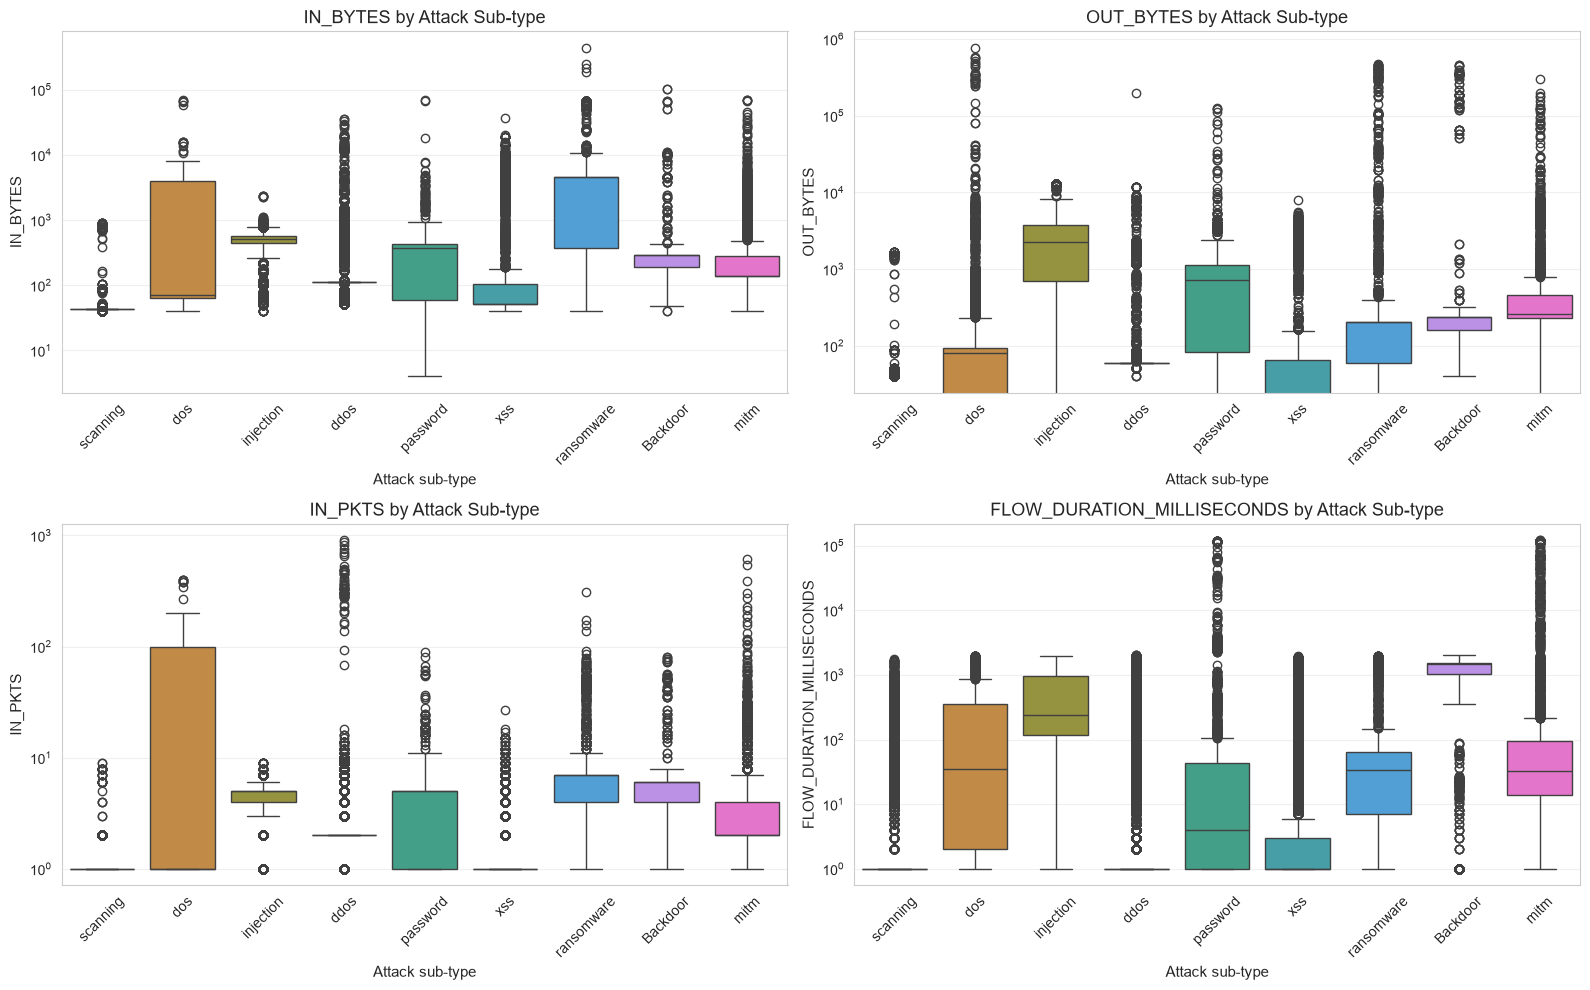

In [97]:
compare_attacks = df_attacks[df_attacks['Attack'].isin(selected_attacks)]
features = ['IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'FLOW_DURATION_MILLISECONDS']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, feat in zip(axes.ravel(), features):
    sns.boxplot(data=compare_attacks, x='Attack', y=feat, ax=ax, palette='husl')
    ax.set_yscale('log')
    ax.set_xlabel('Attack sub-type')
    ax.set_ylabel(feat)
    ax.set_title(f'{feat} by Attack Sub-type')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


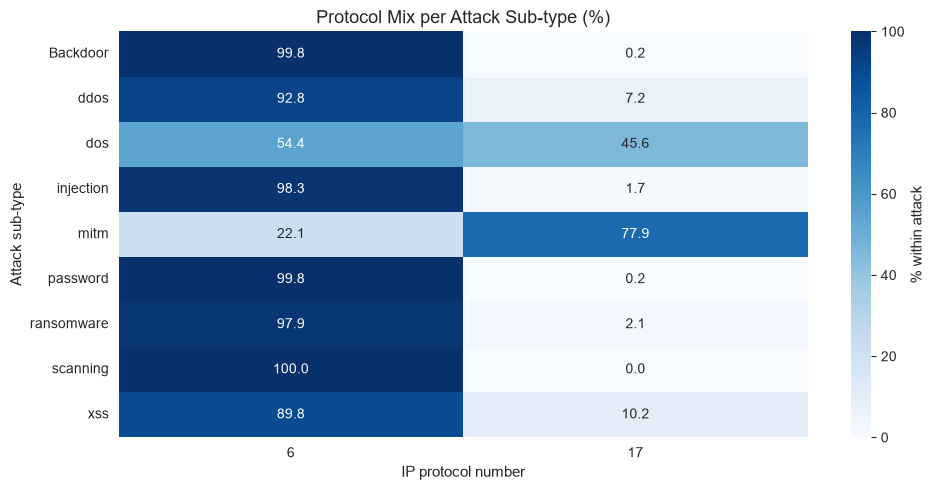

In [98]:
proto_attack = pd.crosstab(compare_attacks['Attack'], compare_attacks['PROTOCOL'],
                           normalize='index') * 100

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(proto_attack.round(1), annot=True, fmt='.1f', cmap='Blues', ax=ax,
            cbar_kws={'label': '% within attack'})
ax.set_xlabel('IP protocol number')
ax.set_ylabel('Attack sub-type')
ax.set_title('Protocol Mix per Attack Sub-type (%)')
plt.tight_layout()
plt.show()


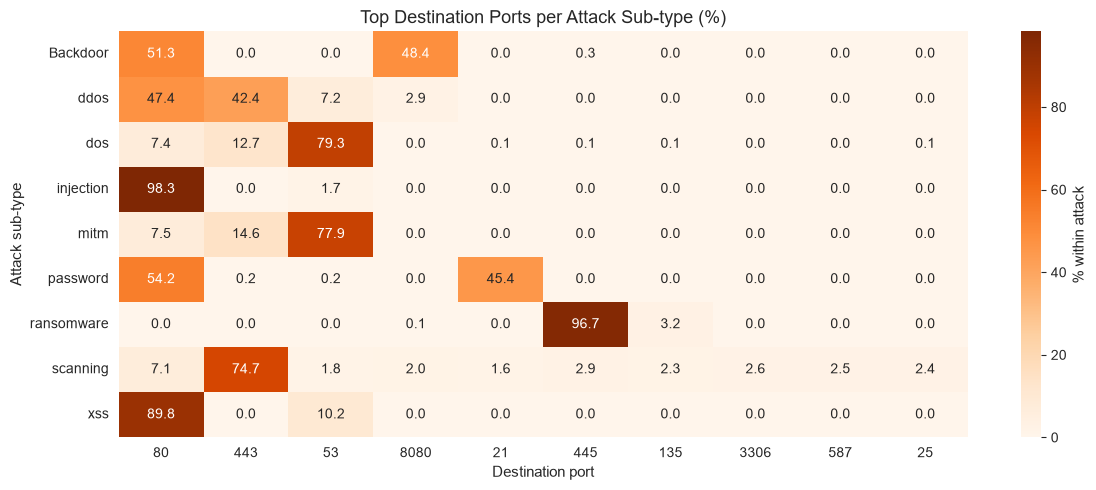

In [99]:
top_ports = compare_attacks['L4_DST_PORT'].value_counts().head(10).index
port_table = pd.crosstab(compare_attacks['Attack'], compare_attacks['L4_DST_PORT'])
port_table = port_table.reindex(columns=top_ports, fill_value=0)
port_pct = port_table.div(port_table.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(port_pct.round(1), annot=True, fmt='.1f', cmap='Oranges', ax=ax,
            cbar_kws={'label': '% within attack'})
ax.set_xlabel('Destination port')
ax.set_ylabel('Attack sub-type')
ax.set_title('Top Destination Ports per Attack Sub-type (%)')
plt.tight_layout()
plt.show()


## 9. Benign vs attack statistics

Build a comparison table from a benign sample plus the stratified attack sample, adding a `Class` column (`Benign` or the attack name) so every row is easy to filter.


In [100]:
benign_pool = df_sample[df_sample['Label'] == 0]
benign_sample = benign_pool.sample(n=min(50_000, len(benign_pool)), random_state=42)

df_compare = pd.concat([benign_sample, df_attacks], ignore_index=True)
df_compare['Class'] = df_compare['Attack']
df_compare.loc[df_compare['Label'] == 0, 'Class'] = 'Benign'

key_features = [
    'FLOW_DURATION_MILLISECONDS', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS',
    'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'MIN_TTL', 'MAX_TTL',
    'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT',
]

stats_by_label = df_compare.groupby('Label')[key_features].agg(['mean', 'median', 'std'])
stats_by_label.index = stats_by_label.index.map({0: 'Benign', 1: 'Attack'})
display(stats_by_label.round(2))


FLOW_DURATION_MILLISECONDS                 IN_BYTES                  \
                             mean median      std     mean median      std   
Label                                                                        
Benign                     109.03    1.0   353.39    64.89   44.0   337.11   
Attack                     511.87    9.0  4049.13   702.92  112.0  2897.69   

       OUT_BYTES                  IN_PKTS  ... MIN_TTL MAX_TTL                \
            mean median       std    mean  ...     std    mean median    std   
Label                                      ...                                 
Benign      9.34    0.0     56.70    1.35  ...   16.59    5.85    0.0  18.29   
Attack   1232.23   81.0  10864.85   10.09  ...   52.31   53.35   64.0  52.31   

       LONGEST_FLOW_PKT                SHORTEST_FLOW_PKT                
                   mean median     std              mean median    std  
Label                                                                   
Benign            45.27   44.0   48.18             42.03   44.0  11.06  
Attack           352.25   60.0  542.00             53.88   52.0  76.03  

[2 rows x 33 columns]

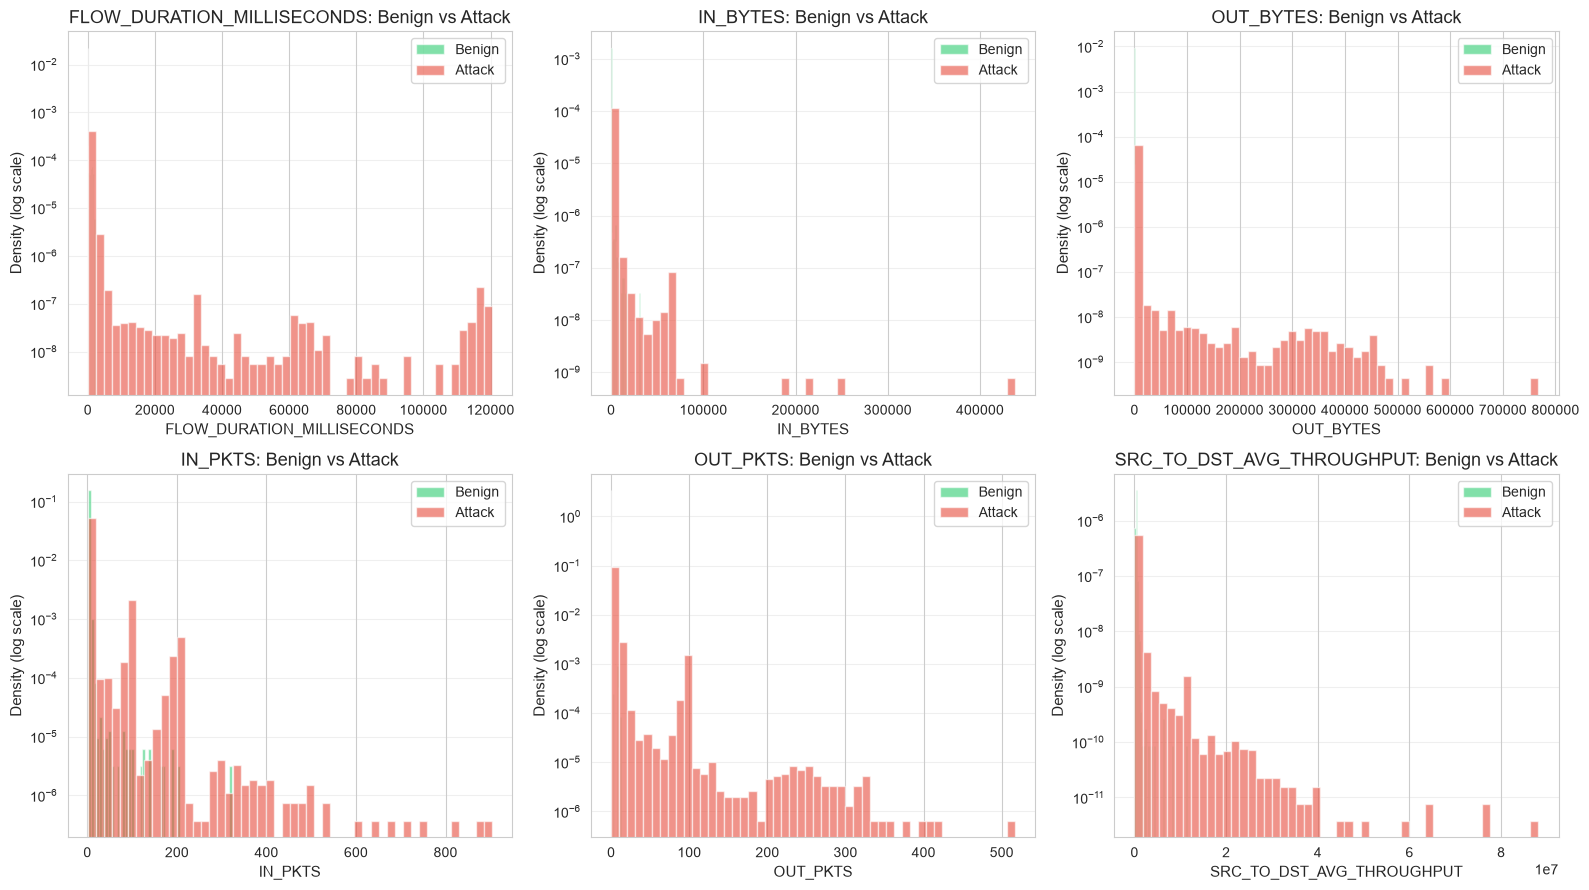

In [101]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feat in zip(axes.ravel(), key_features[:6]):
    for label, color in [(0, '#2ecc71'), (1, '#e74c3c')]:
        vals = df_compare.loc[df_compare['Label'] == label, feat]
        ax.hist(vals, bins=50, alpha=0.6, density=True, color=color,
                label='Benign' if label == 0 else 'Attack')
    ax.set_yscale('log')
    ax.set_xlabel(feat)
    ax.set_ylabel('Density (log scale)')
    ax.set_title(f'{feat}: Benign vs Attack')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


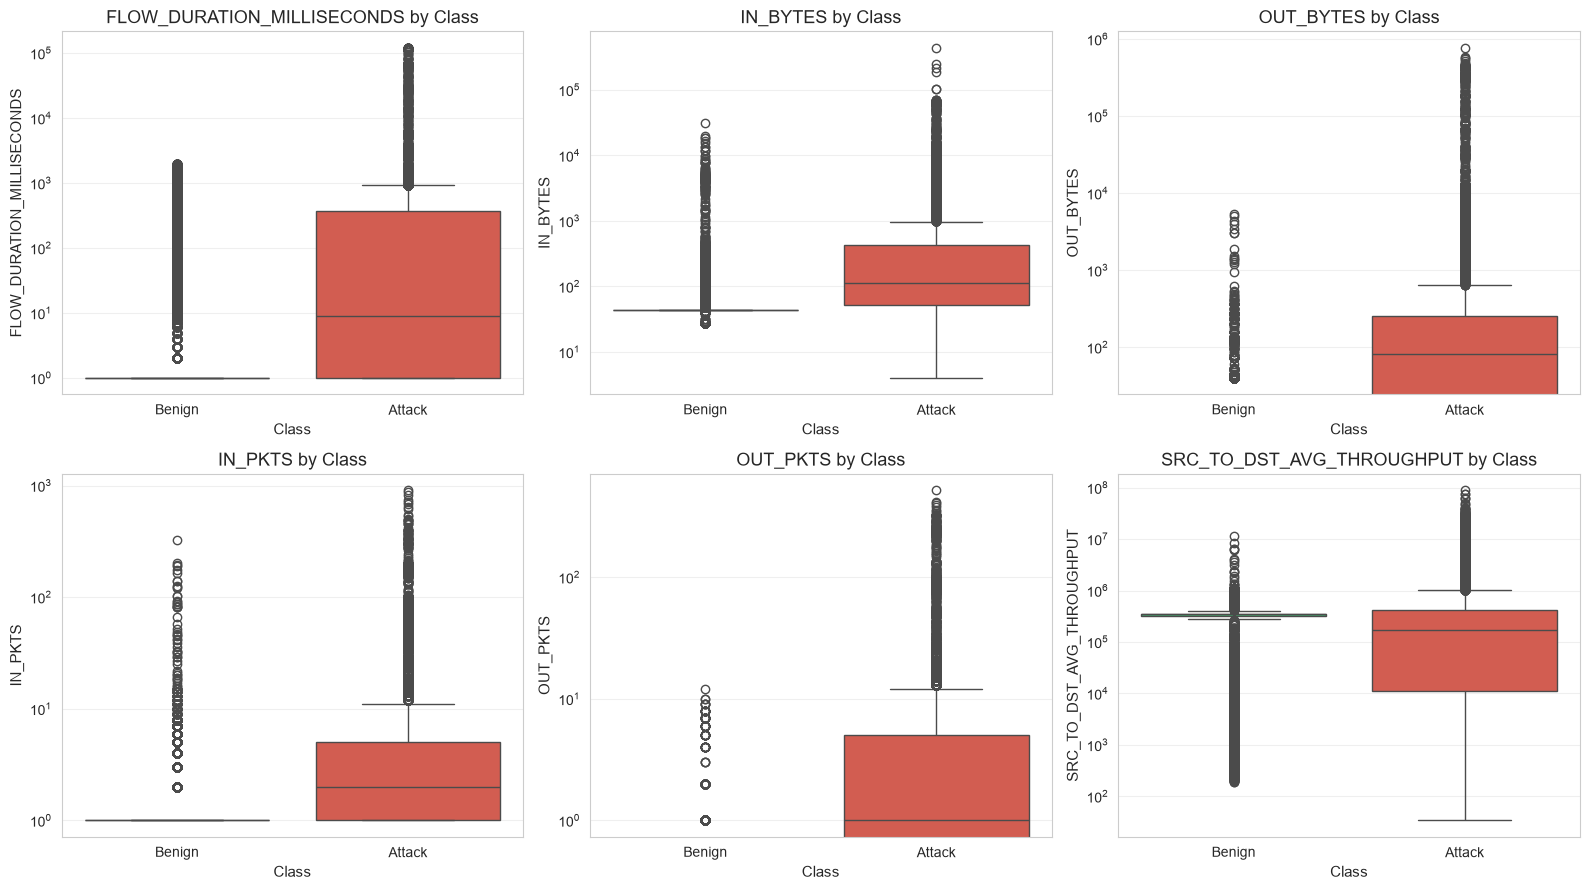

In [102]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feat in zip(axes.ravel(), key_features[:6]):
    sns.boxplot(data=df_compare, x='Label', y=feat, ax=ax,
                palette=['#2ecc71', '#e74c3c'])
    ax.set_yscale('log')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Benign', 'Attack'])
    ax.set_xlabel('Class')
    ax.set_ylabel(feat)
    ax.set_title(f'{feat} by Class')
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Protocol analysis

Full-file IP protocol counts, plus the protocol mix inside each attack type.


,Protocol,Flows,Name,Percent
0,6,22875991,TCP,83.12
2,17,4402790,UDP,16.00
1,1,215377,ICMP,0.78
3,2,24847,IGMP,0.09
4,58,1255,ICMPv6,0.00


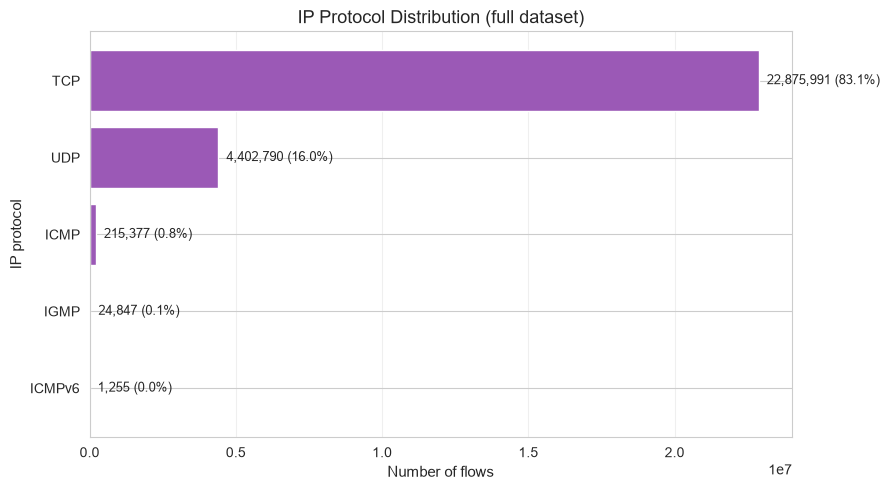

In [103]:
PROTOCOL_MAP = {1: 'ICMP', 2: 'IGMP', 6: 'TCP', 17: 'UDP', 47: 'GRE',
                50: 'ESP', 51: 'AH', 58: 'ICMPv6', 89: 'OSPF', 132: 'SCTP'}

proto_df = pd.DataFrame(proto_counts.items(), columns=['Protocol', 'Flows'])
proto_df['Protocol'] = pd.to_numeric(proto_df['Protocol'], errors='coerce').fillna(-1).astype(int)
proto_df['Name'] = proto_df['Protocol'].map(PROTOCOL_MAP).fillna('Other')
proto_df['Percent'] = (proto_df['Flows'] / total_rows * 100).round(2)
proto_df = proto_df.sort_values('Flows', ascending=False)
display(proto_df)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(proto_df['Name'][::-1], proto_df['Flows'][::-1], color='#9b59b6')
ax.set_xlabel('Number of flows')
ax.set_ylabel('IP protocol')
ax.set_title('IP Protocol Distribution (full dataset)')
for i, (v, p) in enumerate(zip(proto_df['Flows'][::-1], proto_df['Percent'][::-1])):
    ax.text(v, i, f'  {v:,} ({p:.1f}%)', va='center', fontsize=9)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


## 11. Port analysis

Top source and destination ports over the full file, using well-known service names where possible.


,Port,Flows,Service
0,80,5648073,HTTP
1,443,2771541,HTTPS
2,53,2375961,DNS
3,51642,883791,Other
4,52970,377506,Other
5,57856,252636,Other
6,0,245909,Other
7,21,221098,FTP
8,60899,218187,Other
9,8080,153792,HTTP-Alt


,Port,Flows,Service
0,443,3378364,HTTPS
1,53,1868530,DNS
2,80,1533352,HTTP
3,0,241831,Ephemeral/Other
4,1880,142452,Ephemeral/Other
5,8080,70122,HTTP-Alt
6,52970,32450,Ephemeral/Other
7,5353,16872,Ephemeral/Other
8,55815,15647,Ephemeral/Other
9,45061,12969,Ephemeral/Other


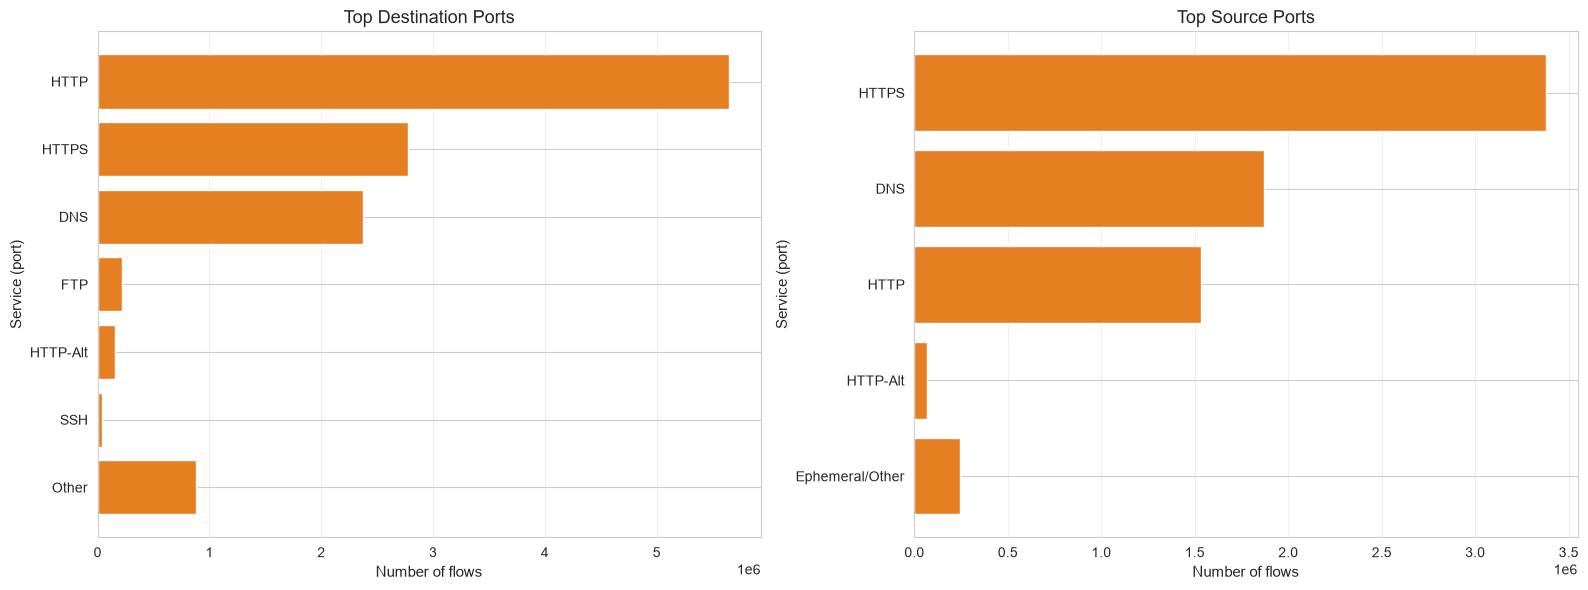

In [104]:
WELL_KNOWN_PORTS = {
    20: 'FTP-DATA', 21: 'FTP', 22: 'SSH', 23: 'TELNET', 25: 'SMTP',
    53: 'DNS', 67: 'DHCP', 68: 'DHCP', 69: 'TFTP', 80: 'HTTP',
    110: 'POP3', 123: 'NTP', 139: 'NetBIOS', 143: 'IMAP', 161: 'SNMP',
    443: 'HTTPS', 445: 'SMB', 993: 'IMAPS', 995: 'POP3S', 1433: 'MSSQL',
    3306: 'MySQL', 3389: 'RDP', 5432: 'PostgreSQL', 5900: 'VNC',
    8080: 'HTTP-Alt', 27017: 'MongoDB',
}

dst_df = pd.DataFrame(dst_port_counts.items(), columns=['Port', 'Flows'])
dst_df['Service'] = dst_df['Port'].map(WELL_KNOWN_PORTS).fillna('Other')
dst_df = dst_df.sort_values('Flows', ascending=False).head(15)

src_df = pd.DataFrame(src_port_counts.items(), columns=['Port', 'Flows'])
src_df['Service'] = src_df['Port'].map(WELL_KNOWN_PORTS).fillna('Ephemeral/Other')
src_df = src_df.sort_values('Flows', ascending=False).head(15)

display(dst_df.reset_index(drop=True))
display(src_df.reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, frame, title in [(axes[0], dst_df, 'Top Destination Ports'),
                         (axes[1], src_df, 'Top Source Ports')]:
    ax.barh(frame['Service'][::-1], frame['Flows'][::-1], color='#e67e22')
    ax.set_xlabel('Number of flows')
    ax.set_ylabel('Service (port)')
    ax.set_title(title)
    ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


## 12. IP address analysis

How many endpoints are there, which IPs dominate, and how many unique IPs each attack type touches.


Unique source IPs      : 60
Unique destination IPs : 330


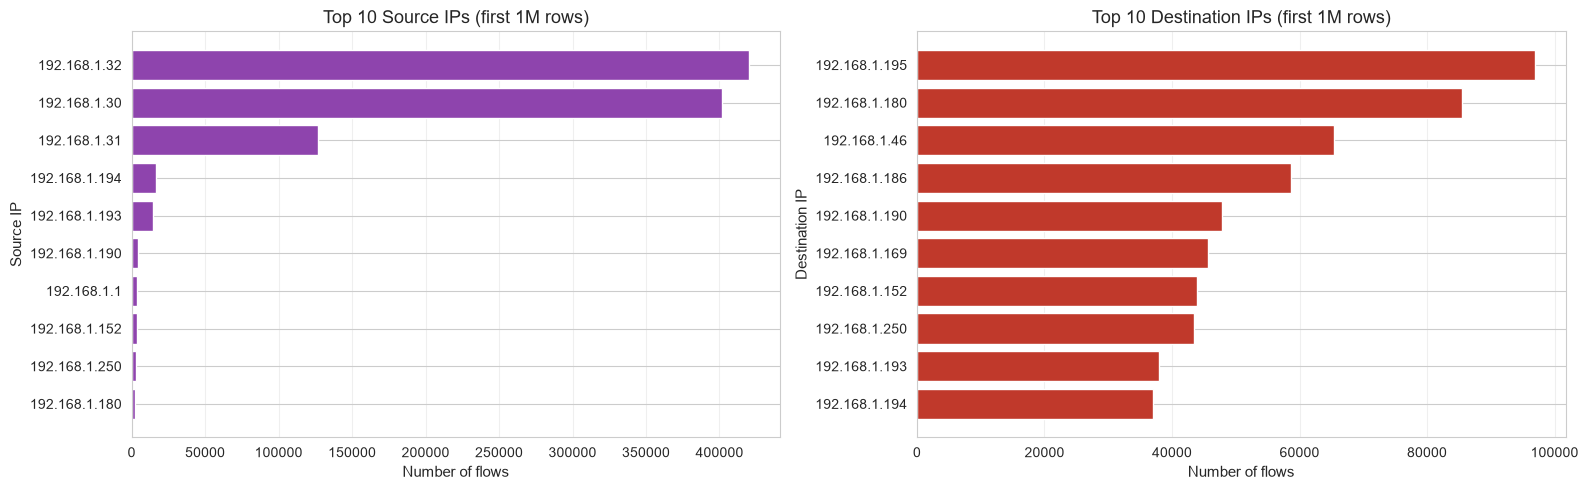

,UniqueSrcIPs,UniqueDstIPs
Attack,,
scanning,10,234
dos,7,110
ddos,4,13
Backdoor,3,5
ransomware,3,4
mitm,2,106
injection,2,11
password,2,27
xss,2,8


In [105]:
print(f'Unique source IPs      : {df_sample["IPV4_SRC_ADDR"].nunique():,}')
print(f'Unique destination IPs : {df_sample["IPV4_DST_ADDR"].nunique():,}')

top_src = df_sample['IPV4_SRC_ADDR'].value_counts().head(10)
top_dst = df_sample['IPV4_DST_ADDR'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].barh(top_src.index[::-1], top_src.values[::-1], color='#8e44ad')
axes[0].set_xlabel('Number of flows')
axes[0].set_ylabel('Source IP')
axes[0].set_title('Top 10 Source IPs (first 1M rows)')
axes[0].grid(axis='x', alpha=0.3)

axes[1].barh(top_dst.index[::-1], top_dst.values[::-1], color='#c0392b')
axes[1].set_xlabel('Number of flows')
axes[1].set_ylabel('Destination IP')
axes[1].set_title('Top 10 Destination IPs (first 1M rows)')
axes[1].grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

attack_ips = df_attacks.groupby('Attack')[['IPV4_SRC_ADDR', 'IPV4_DST_ADDR']].nunique()
attack_ips.columns = ['UniqueSrcIPs', 'UniqueDstIPs']
display(attack_ips.sort_values('UniqueSrcIPs', ascending=False))


## 13. Temporal analysis

Flow volume by hour of day and over the capture timeline.


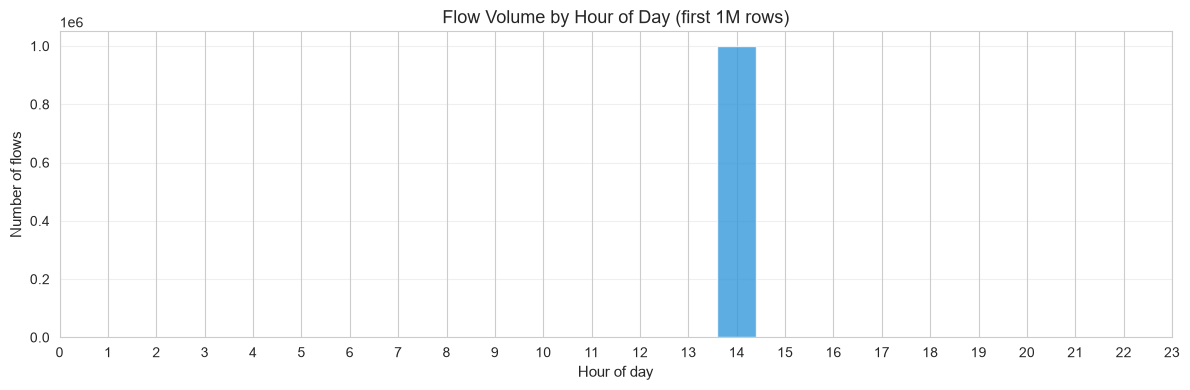

In [106]:
df_sample['flow_start_dt'] = pd.to_datetime(df_sample['FLOW_START_MILLISECONDS'], unit='ms')
hourly = df_sample['flow_start_dt'].dt.hour.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(hourly.index, hourly.values, color='#3498db', alpha=0.8)
ax.set_xlabel('Hour of day')
ax.set_ylabel('Number of flows')
ax.set_title('Flow Volume by Hour of Day (first 1M rows)')
ax.set_xticks(range(24))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


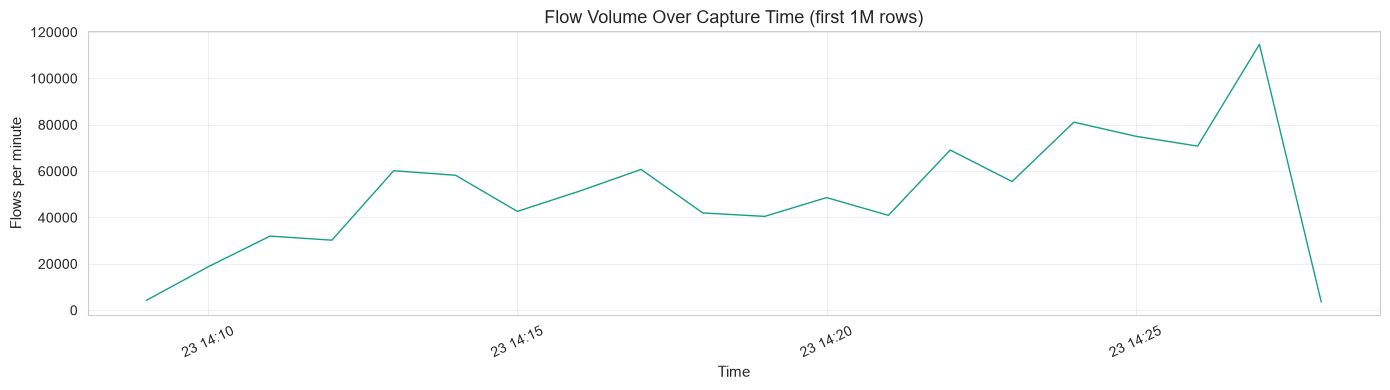

In [107]:
per_minute = df_sample.set_index('flow_start_dt').resample('1min').size()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(per_minute.index, per_minute.values, color='#16a085', linewidth=1)
ax.set_xlabel('Time')
ax.set_ylabel('Flows per minute')
ax.set_title('Flow Volume Over Capture Time (first 1M rows)')
ax.grid(alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


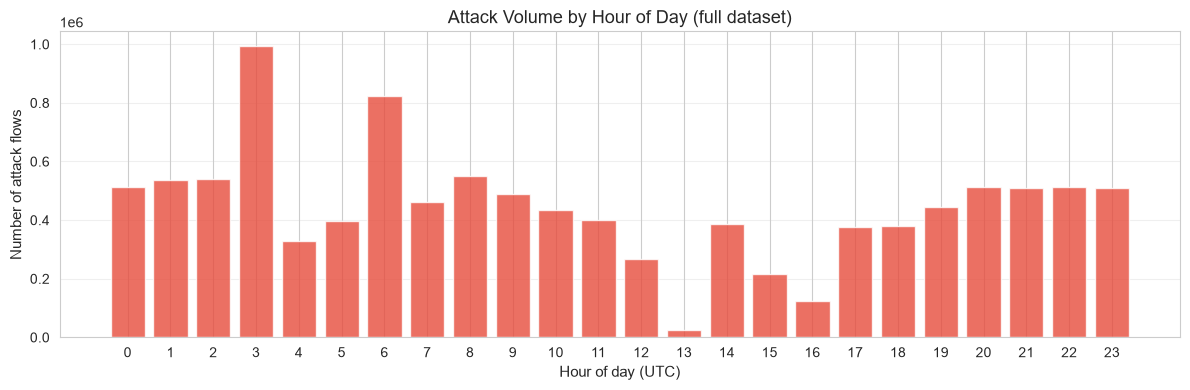

In [108]:
attack_hour = pd.Series(pd.to_datetime(attack_times, unit='ms').hour).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(attack_hour.index, attack_hour.values, color='#e74c3c', alpha=0.8)
ax.set_xlabel('Hour of day (UTC)')
ax.set_ylabel('Number of attack flows')
ax.set_title('Attack Volume by Hour of Day (full dataset)')
ax.set_xticks(range(24))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## 14. Feature correlation

Correlation among key numeric features. Strongly correlated pairs are redundant for modelling.


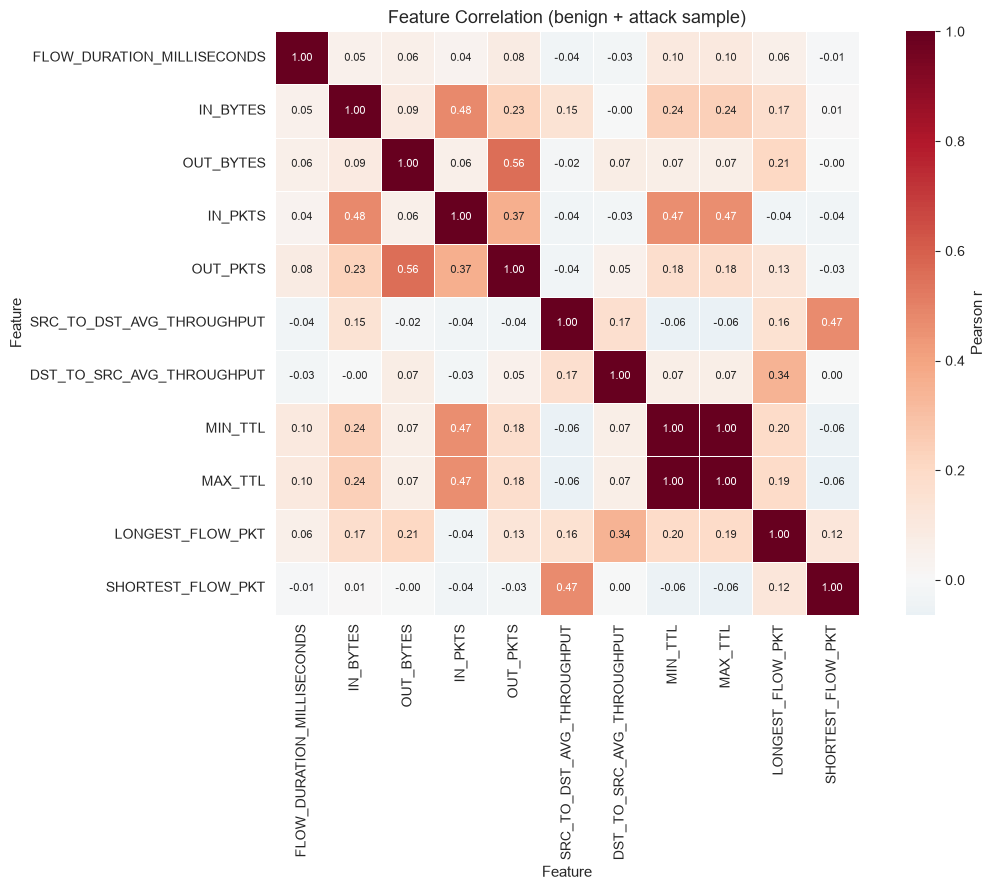

Pairs with |r| > 0.8:


,Feature 1,Feature 2,r
0,MIN_TTL,MAX_TTL,0.999


In [109]:
corr = df_compare[key_features].corr()

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True,
            linewidths=0.5, ax=ax, annot_kws={'size': 8},
            cbar_kws={'label': 'Pearson r'})
ax.set_xlabel('Feature')
ax.set_ylabel('Feature')
ax.set_title('Feature Correlation (benign + attack sample)')
plt.tight_layout()
plt.show()

high = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        value = corr.iloc[i, j]
        if abs(value) > 0.8:
            high.append({'Feature 1': corr.columns[i],
                         'Feature 2': corr.columns[j],
                         'r': round(value, 3)})
print('Pairs with |r| > 0.8:')
display(pd.DataFrame(high) if high else pd.DataFrame({'Note': ['None found']}))


## 15. Missing and infinite values

Check the sample for missing (`NaN`) and infinite (`inf`) values.


In [110]:
missing = df_sample.isnull().sum()
missing_df = (missing[missing > 0]
              .rename('MissingCount')
              .to_frame())
missing_df['MissingPercent'] = (missing_df['MissingCount'] / len(df_sample) * 100).round(4)
print(f'Columns with missing values: {len(missing_df)}')
display(missing_df.sort_values('MissingCount', ascending=False) if len(missing_df) else pd.DataFrame({'Note': ['No missing values']}))

numeric = df_sample.select_dtypes(include=[np.number])
inf_counts = np.isinf(numeric).sum()
inf_df = inf_counts[inf_counts > 0].rename('InfiniteCount').to_frame()
print(f'Columns with infinite values: {len(inf_df)}')
display(inf_df.sort_values('InfiniteCount', ascending=False) if len(inf_df) else pd.DataFrame({'Note': ['No infinite values']}))


Columns with missing values: 0


,Note
0,No missing values


Columns with infinite values: 0


,Note
0,No infinite values


## 16. Summary & key insights

The next cell prints the headline numbers directly from the full-dataset scan.


In [111]:
print('=' * 60)
print('NF-ToN-IoT v3 - DATASET SUMMARY')
print('=' * 60)
print(f'Total flows          : {total_rows:,}')
print(f'Benign               : {label_counts[0]:,} ({label_counts[0] / total_rows * 100:.1f}%)')
print(f'Attack               : {label_counts[1]:,} ({label_counts[1] / total_rows * 100:.1f}%)')
print(f'Attack types         : {len(attack_counts)}')
print(f'Attack blocks (runs) : {n_runs:,}')
print(f'Mixing index         : {mixing_index:.4f} -> {verdict}')
print()
print('Per-attack flow counts:')
for name in attack_df['Attack']:
    print(f'  {name:12s} {attack_counts[name]:>12,}  ({attack_df.set_index("Attack").loc[name, "PercentOfAttacks"]:.2f}% of attacks)')
print()
print('Most common attack   :', attack_df.iloc[0]['Attack'])
print('Rarest attack        :', attack_df.iloc[-1]['Attack'])


NF-ToN-IoT v3 - DATASET SUMMARY
Total flows          : 27,520,260
Benign               : 16,792,214 (61.0%)
Attack               : 10,728,046 (39.0%)
Attack types         : 9
Attack blocks (runs) : 9
Mixing index         : 0.0000 -> mostly BLOCKED / sequential

Per-attack flow counts:
  ddos            4,141,256  (38.60% of attacks)
  xss             2,834,435  (26.42% of attacks)
  password        1,594,777  (14.87% of attacks)
  scanning        1,358,977  (12.67% of attacks)
  injection         381,777  (3.56% of attacks)
  dos               203,456  (1.90% of attacks)
  Backdoor          203,384  (1.90% of attacks)
  mitm                6,013  (0.06% of attacks)
  ransomware          3,971  (0.04% of attacks)

Most common attack   : ddos
Rarest attack        : ransomware


### Key takeaways

1. **All 9 attack types are present**, but they are not evenly distributed — `ddos`, `xss` and `password` dominate, while `ransomware` and `mitm` are rare.
2. **The first 1M rows are not representative.** They contain benign + `scanning` only; always scan the full file for attack-level conclusions.
3. **Attack ordering is measurable.** The mixing index and transition matrix show whether attacks arrive in blocks or interleave. Use the timeline to see the pattern visually.
4. **Per-attack behaviour differs.** Duration, bytes, ports and protocols vary strongly by attack type, which is why multiclass models can outperform a single binary detector.
5. **Time-aware splits matter.** Because flows are time-ordered and attacks can cluster, random splits may leak future patterns into training.

### Recommendations

- Use time-aware train/validation/test splits.
- Handle class imbalance with stratified sampling, class weights, or focal loss.
- Evaluate with macro-F1 and per-class recall, not accuracy alone.
- Drop one of each highly correlated feature pair.
- Treat `ransomware` and `mitm` as low-support classes; report per-class metrics.

---

*End of notebook*
